<a href="https://colab.research.google.com/github/ghcarvalho-unifesp/projeto-pluma-modelagem-unifesp/blob/main/ModelagemComputacional_Projeto_Pluma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pluma de fumaça: dados ERA5 e segmentação com o SAM

**Modelagem Computacional · Profa. Raquel Lobosco**
**Aluno:** Gabriel Henrique Carvalho

Este notebook tem três partes:

- **Parte A:** instalação, Google Drive e dados de vento ERA5 do dia da foto (feito em aula).
- **Parte B:** primeiras tentativas automáticas de achar a fumaça (YOLO e SAM 3 com texto).
- **Parte C:** segmentação com o SAM usando prompts manuais (caixa e pontos positivos/negativos), comparação de configurações, melhorias e análise de iluminação, contraste e fumaça × nuvem.

> Rodar com GPU: **Ambiente de execução → Alterar o tipo de ambiente de execução → T4 GPU**. Em CPU funciona, só que bem mais devagar.

# Parte A: preparação e dados ERA5

In [37]:
# Instalação das bibliotecas necessárias no Colab
!pip -q install xarray netCDF4
!pip install -U ultralytics
!pip install git+https://github.com/ultralytics/CLIP.git

import os, zipfile, glob, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
!pip install cdsapi
from ultralytics import YOLO
import urllib.request
from ultralytics.models.sam import SAM3SemanticPredictor
import cdsapi

  Cloning https://github.com/ultralytics/CLIP.git to /tmp/pip-req-build-wq0quu17
  Running command git clone --filter=blob:none --quiet https://github.com/ultralytics/CLIP.git /tmp/pip-req-build-wq0quu17
  Resolved https://github.com/ultralytics/CLIP.git to commit 7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
# A chave da API do CDS NÃO fica escrita no notebook, porque ele vai para o GitHub.
# Ao rodar, cole a chave na caixa que aparece (ela fica em cds.climate.copernicus.eu → seu perfil).
from getpass import getpass
CDS_KEY = getpass("Chave da API do CDS: ")

dataset = "derived-era5-single-levels-daily-statistics"
request = {
    "product_type": "reanalysis",
    "variable": ["10m_u_component_of_wind", "10m_v_component_of_wind", "2m_temperature"],
    "year": "2026",
    "month": ["08"],
    "day": ["25"],
    "daily_statistic": "daily_mean",
    "time_zone": "utc-03:00",
    "frequency": "3_hourly",
    "area": [-23.25, -46.75, -23.75, -46.25],
}
client = cdsapi.Client(url="https://cds.climate.copernicus.eu/api", key=CDS_KEY)
ARQUIVO_ZIP_BAIXADO = client.retrieve(dataset, request).download()
print("Baixado:", ARQUIVO_ZIP_BAIXADO)

Chave da API do CDS: ··········


2026-10-20 01:23:56,818 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 

24a1328b70bedf11840251347b02504c.zip:   0%|          | 0.00/74.3k [00:00<?, ?B/s]

Baixado: 24a1328b70bedf11840251347b02504c.zip


In [40]:
PASTA_DRIVE = "/content/drive/MyDrive/projeto_pluma"
NOME_ZIP = os.path.basename(ARQUIVO_ZIP_BAIXADO)  # nome gerado pelo CDS
# O arquivo ZIP foi baixado diretamente para /content/, então ajustamos o caminho.
CAMINHO_ZIP = os.path.join("/content", NOME_ZIP)

# A extração em /content costuma ser mais rápida durante a aula
PASTA_EXTRACAO = "/content/era5_pluma"
PASTA_SAIDA = os.path.join(PASTA_DRIVE, "csv_era5")
os.makedirs(PASTA_EXTRACAO, exist_ok=True)
os.makedirs(PASTA_SAIDA, exist_ok=True)

assert os.path.exists(CAMINHO_ZIP), f"ZIP não encontrado: {CAMINHO_ZIP}"
with zipfile.ZipFile(CAMINHO_ZIP, "r") as z:
    z.extractall(PASTA_EXTRACAO)

print("Arquivos extraídos:")
for p in sorted(Path(PASTA_EXTRACAO).rglob("*")):
    if p.is_file(): print(p)

Arquivos extraídos:
/content/era5_pluma/10m_u_component_of_wind_stream-oper_daily-mean.nc
/content/era5_pluma/10m_v_component_of_wind_0_daily-mean.nc
/content/era5_pluma/2m_temperature_0_daily-mean.nc


In [41]:
import shutil

# Caminho original da imagem no Google Drive
CAMINHO_ORIGINAL_IMAGEM = "/content/drive/MyDrive/pluma.jpg"

# Caminho de destino no /content/ com o novo nome e extensão
CAMINHO_NOVO_IMAGEM = "/content/pluma.png"

# Copia o arquivo
shutil.copyfile(CAMINHO_ORIGINAL_IMAGEM, CAMINHO_NOVO_IMAGEM)

print(f"Imagem copiada de '{CAMINHO_ORIGINAL_IMAGEM}' para '{CAMINHO_NOVO_IMAGEM}'")

Imagem copiada de '/content/drive/MyDrive/pluma.jpg' para '/content/pluma.png'


In [42]:
# Inspeção dos NetCDF e identificação das variáveis
arquivos_nc = sorted(glob.glob(f"{PASTA_EXTRACAO}/**/*.nc", recursive=True))
assert arquivos_nc, "Nenhum arquivo NetCDF foi encontrado."

for caminho in arquivos_nc:
    ds = xr.open_dataset(caminho)
    print("\nArquivo:", os.path.basename(caminho))
    print("Variáveis:", list(ds.data_vars))
    print("Dimensões:", dict(ds.sizes))
    print("Coordenadas:", list(ds.coords))
    ds.close()


Arquivo: 10m_u_component_of_wind_stream-oper_daily-mean.nc
Variáveis: ['u10']
Dimensões: {'valid_time': 1, 'latitude': 3, 'longitude': 3}
Coordenadas: ['number', 'latitude', 'longitude', 'valid_time']

Arquivo: 10m_v_component_of_wind_0_daily-mean.nc
Variáveis: ['v10']
Dimensões: {'valid_time': 1, 'latitude': 3, 'longitude': 3}
Coordenadas: ['number', 'latitude', 'longitude', 'valid_time']

Arquivo: 2m_temperature_0_daily-mean.nc
Variáveis: ['t2m']
Dimensões: {'valid_time': 1, 'latitude': 3, 'longitude': 3}
Coordenadas: ['number', 'latitude', 'longitude', 'valid_time']


In [43]:
def netcdf_para_csv(caminho_nc, pasta_saida):
    ds = xr.open_dataset(caminho_nc)
    nome = Path(caminho_nc).stem + ".csv"
    caminho_csv = os.path.join(pasta_saida, nome)
    df = ds.to_dataframe().reset_index()
    df.to_csv(caminho_csv, index=False)
    ds.close()
    print(f"{nome}: {df.shape[0]} linhas × {df.shape[1]} colunas")
    return df, caminho_csv

tabelas = {}
for caminho in arquivos_nc:
    chave = Path(caminho).stem
    tabelas[chave], _ = netcdf_para_csv(caminho, PASTA_SAIDA)

print("\nCSV salvos em:", PASTA_SAIDA)
print(os.listdir(PASTA_SAIDA))

10m_u_component_of_wind_stream-oper_daily-mean.csv: 9 linhas × 5 colunas
10m_v_component_of_wind_0_daily-mean.csv: 9 linhas × 5 colunas
2m_temperature_0_daily-mean.csv: 9 linhas × 5 colunas

CSV salvos em: /content/drive/MyDrive/projeto_pluma/csv_era5
['data_stream-oper_stepType-instant.csv', 'data_stream-oper_stepType-accum.csv', '10m_u_component_of_wind_stream-oper_daily-mean.csv', '10m_v_component_of_wind_0_daily-mean.csv', '2m_temperature_0_daily-mean.csv']


In [44]:
df_component_u = pd.read_csv("/content/drive/MyDrive/projeto_pluma/csv_era5/10m_u_component_of_wind_stream-oper_daily-mean.csv")

In [45]:
df_component_u

,valid_time,latitude,longitude,u10,number
0,2026-08-25,-23.25,-46.75,-2.293083,0
1,2026-08-25,-23.25,-46.50,-2.154289,0
2,2026-08-25,-23.25,-46.25,-1.748528,0
3,2026-08-25,-23.50,-46.75,-2.509636,0
4,2026-08-25,-23.50,-46.50,-2.436150,0
5,2026-08-25,-23.50,-46.25,-1.702019,0
6,2026-08-25,-23.75,-46.75,-1.529411,0
7,2026-08-25,-23.75,-46.50,-1.297356,0
8,2026-08-25,-23.75,-46.25,-1.388542,0


# Parte B: primeiras tentativas automáticas

Antes de dar prompts ao SAM, testamos se dava para achar a fumaça sem intervenção humana.

**B.1 YOLO genérico.** O YOLO pré-treinado conhece as 80 classes do conjunto COCO (pessoas, carros, animais…), e **fumaça não é uma delas**. Por isso ele só encontra os carros e o caminhão da foto.

In [46]:
model = YOLO("yolo26n.pt")
results = model("/content/drive/MyDrive/pluma.jpg")


image 1/1 /content/drive/MyDrive/pluma.jpg: 640x480 4 cars, 1 truck, 15.2ms
Speed: 5.3ms preprocess, 15.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


**B.2 SAM 3 com prompt de texto ("smoke").** O SAM 3 aceita texto como prompt, então o nosso prompt foi escolhido para encontrar fumaça na imagem. Não roda, porque o arquivo do modelo SAM 3 precisa de autorização para baixar.
A célula abaixo registra a tentativa sem interromper o notebook.

In [47]:
try:
    from ultralytics.models.sam import SAM3SemanticPredictor

    # Initialize predictor with configuration
    overrides = {
        "conf": 0.25,
        "task": "segment",
        "mode": "predict",
        "model": "sam_b.pt", # Alterado de 'sam3.pt' para 'sam_b.pt' para um modelo SAM padrão que a Ultralytics pode baixar automaticamente
        "quantize": 16,  # Use FP16 for faster inference
        "save": True,
    }
    predictor = SAM3SemanticPredictor(overrides=overrides)

    # Set image once for multiple queries
    predictor.set_image("/content/pluma.png")

    # Query with multiple text prompts
    results = predictor(text=["smoke"])

except Exception as e:
    print("SAM 3 com texto não rodou:", type(e).__name__, e)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
SAM 3 com texto não rodou: FileNotFoundError [Errno 2] No such file or directory: 'sam_b.pt'


**B.3 YOLO treinado para fumaça + SAM 2.** Um detector treinado especificamente para fumaça gera a caixa e o SAM 2 segmenta dentro dela. Nesta foto, porém, o detector **não encontrou fumaça** com confiança de 25 %, provavelmente porque a imagem é diferente das usadas no treino dele (ângulo, distância, iluminação, fundo urbano).

**Conclusão da Parte B:** as abordagens automáticas falharam. Isso justifica a Parte C, em que nós mesmos indicamos ao SAM onde está a pluma.

In [48]:
import cv2, numpy as np

!pip install -q huggingface_hub
from huggingface_hub import hf_hub_download
from ultralytics import YOLO, SAM

pt = hf_hub_download("kittendev/YOLOv8m-smoke-detection", "best.pt")
det = YOLO(pt)
print(det.names)                      # confira o índice da classe "smoke"
sam = SAM("sam2_b.pt")

img = cv2.imread("/content/pluma.png")
assert img is not None

r = det(img, conf=0.25)[0]
smoke_id = [k for k, v in det.names.items() if v.lower() == "smoke"][0]
caixas = r.boxes.xyxy[r.boxes.cls == smoke_id].cpu().numpy()

if len(caixas) == 0:
    print("Nenhuma fumaça detectada.")
else:
    s = sam(img, bboxes=caixas)[0]
    mask = (s.masks.data.cpu().numpy().any(0) * 255).astype(np.uint8)
    mask = cv2.resize(mask, (img.shape[1], img.shape[0]))

    fundo = np.full_like(img, 255)
    recorte = np.where(mask[..., None] == 255, img, fundo)
    x, y, w, h = cv2.boundingRect(mask)
    cv2.imwrite("/content/pluma_recorte.jpg", recorte[y:y+h, x:x+w])
    print("Salvo em /content/pluma_recorte.jpg")

{0: 'smoke'}

0: 640x480 (no detections), 58.7ms
Speed: 2.9ms preprocess, 58.7ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 480)
Nenhuma fumaça detectada.


# Parte C: SAM com prompts manuais

## 1. Instalação e modelo

In [49]:
!pip -q install git+https://github.com/facebookresearch/segment-anything.git
!wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import torch
from PIL import Image
from scipy import ndimage as ndi
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator

device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth").to(device)
predictor = SamPredictor(sam)
print("Dispositivo:", device)

  Preparing metadata (setup.py) ... done
Dispositivo: cuda


## 2. Imagem

Usamos a foto da pluma que já está no Drive (`pluma.jpg`).


In [50]:
# Usamos a mesma foto da Parte A (copiada do Drive para /content/pluma.png)
CAMINHO_IMAGEM = CAMINHO_NOVO_IMAGEM

img = np.array(Image.open(CAMINHO_IMAGEM).convert("RGB"))
escala = 1280 / max(img.shape[:2])   # limita o lado maior a 1280 px para não ficar lento
if escala < 1:
    img = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
H, W = img.shape[:2]
print(f"Imagem: {W} x {H} px")

Imagem: 960 x 1280 px


### 2.1 Grade para escolher as coordenadas dos prompts

A grade abaixo mostra as coordenadas em pixels (x para a direita, y para baixo).

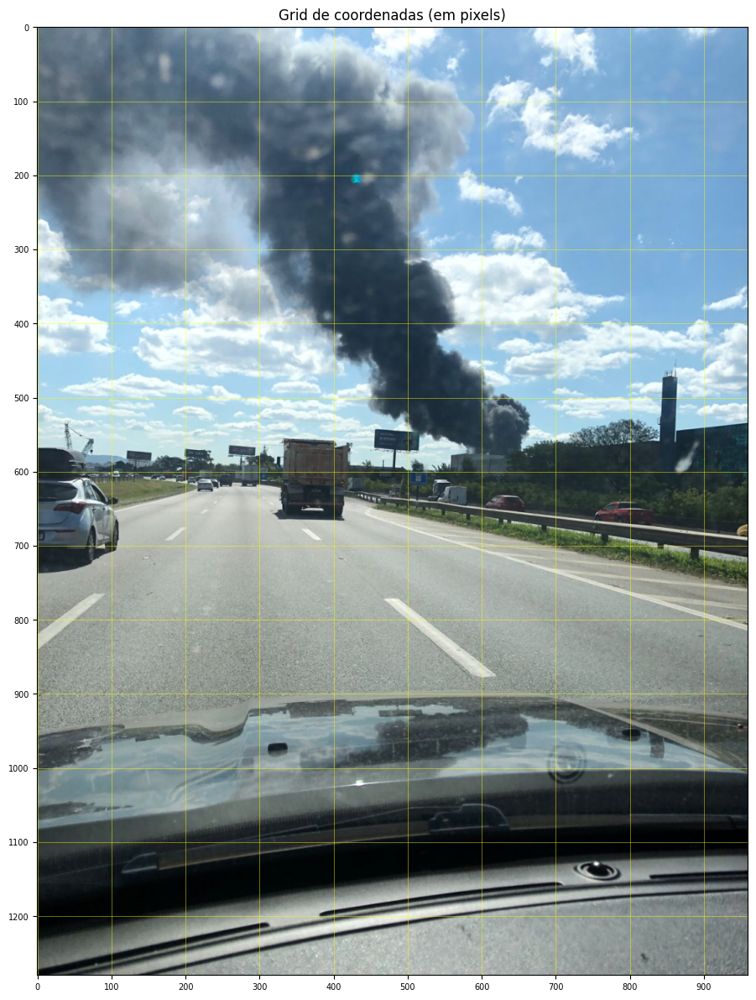

In [51]:
passo = 100 if max(H, W) > 700 else 50
fig, ax = plt.subplots(figsize=(11, 11 * H / W))
ax.imshow(img)
ax.set_xticks(np.arange(0, W, passo)); ax.set_yticks(np.arange(0, H, passo))
ax.grid(color="yellow", alpha=0.5, lw=0.6)
ax.tick_params(labelsize=7)
ax.set_title("Grid de coordenadas (em pixels)")
plt.show()

## 3. Funções auxiliares

In [52]:
COR_MASCARA = np.array([255, 40, 40])

def sobrepor(imagem, mascara, alfa=0.5, cor=COR_MASCARA):
    saida = imagem.astype(float).copy()
    saida[mascara] = (1 - alfa) * saida[mascara] + alfa * cor
    return saida.astype(np.uint8)

def desenhar_prompts(ax, box=None, pts=None, lbls=None):
    if box is not None:
        x0, y0, x1, y1 = box
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                       fill=False, ec="lime", lw=2))
    if pts is not None:
        pts, lbls = np.asarray(pts), np.asarray(lbls)
        ax.scatter(*pts[lbls == 1].T, marker="*", s=220, c="lime", ec="black", lw=1, label="positivo")
        ax.scatter(*pts[lbls == 0].T, marker="X", s=150, c="red", ec="white", lw=1, label="negativo")

def lado_a_lado(imagem, mascara, titulo, box=None, pts=None, lbls=None):
    # imagem original (com prompts) | máscara binária | máscara sobreposta
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.3 * H / W + 0.8))
    ax[0].imshow(imagem); desenhar_prompts(ax[0], box, pts, lbls)
    ax[0].set_title("Original + prompts")
    ax[1].imshow(mascara, cmap="gray"); ax[1].set_title("Máscara binária")
    ax[2].imshow(sobrepor(imagem, mascara)); ax[2].set_title("Máscara sobreposta")
    for a in ax: a.axis("off")
    fig.suptitle(titulo, fontsize=13, weight="bold")
    plt.tight_layout(); plt.show()

def segmentar(box=None, pts=None, lbls=None, mask_input=None):
    # Um ponto sozinho é ambíguo (pode ser só um pedaço da fumaça ou a fumaça toda),
    # então pedimos 3 máscaras e ficamos com a de maior score.
    # Com caixa ou vários pontos o prompt já é específico: uma máscara basta.
    n_pts = 0 if pts is None else len(pts)
    multimask = (box is None and n_pts <= 1)
    masks, scores, logits = predictor.predict(
        point_coords=None if pts is None else np.asarray(pts, dtype=float),
        point_labels=None if pts is None else np.asarray(lbls),
        box=None if box is None else np.asarray(box, dtype=float),
        mask_input=mask_input,
        multimask_output=multimask)
    i = int(np.argmax(scores))
    return masks[i], float(scores[i]), logits[i]

LUM = None  # luminância da imagem, calculada depois de carregar

def luminancia(imagem):
    return (0.299 * imagem[..., 0] + 0.587 * imagem[..., 1] + 0.114 * imagem[..., 2])

def iou(a, b):
    uniao = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / uniao if uniao else np.nan

def metricas(nome, mascara, score):
    # Contraste local: compara a luminância média dentro da máscara com a de um
    # anel de ~15 px em volta dela. Quanto menor a diferença, mais parecida a
    # fumaça é com o que está ao redor, e mais difícil é separar.
    anel = ndi.binary_dilation(mascara, iterations=15) & ~mascara
    _, n_comp = ndi.label(mascara)
    lum_in = LUM[mascara].mean() if mascara.any() else np.nan
    lum_anel = LUM[anel].mean() if anel.any() else np.nan
    return {"configuração": nome, "score SAM": round(score, 3),
            "área (% da imagem)": round(100 * mascara.mean(), 2),
            "componentes": n_comp,
            "lum. dentro": round(lum_in, 1), "lum. anel": round(lum_anel, 1),
            "contraste local": round(abs(lum_in - lum_anel) / 255, 3)}

LUM = luminancia(img)
predictor.set_image(img)
print("Embedding da imagem calculado.")

Embedding da imagem calculado.


## 4. Avaliação inicial

### 4.1 Segmentação automática (sem prompt)

O SAM automático divide a imagem inteira em regiões, sem saber o que procuramos. Isso mostra como ele "enxerga" a cena: se a fumaça vira uma região só, se aparece em pedaços, ou se ela se mistura com o céu e as nuvens.

Regiões encontradas: 44


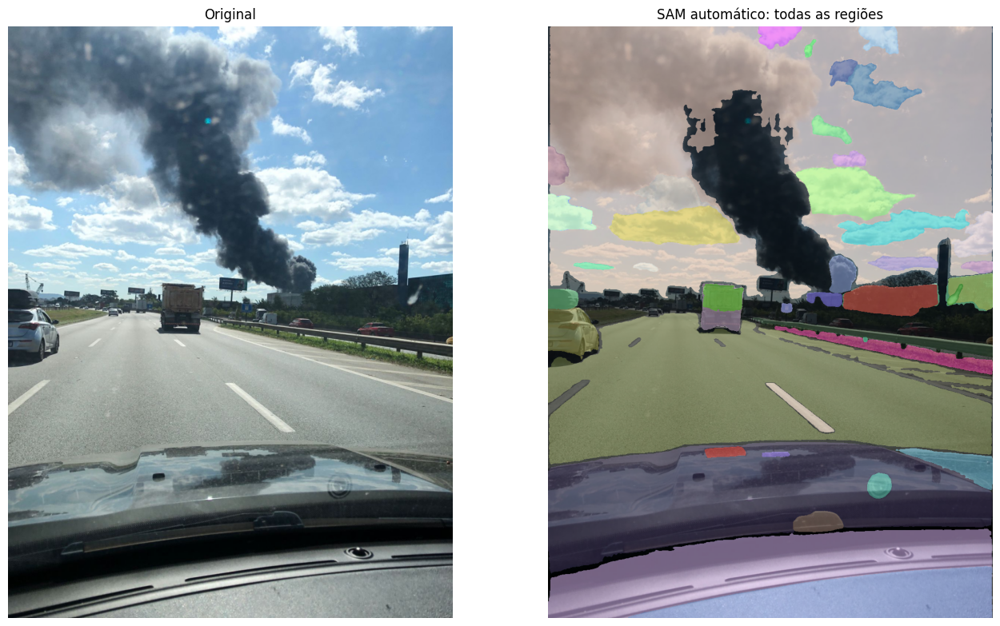

In [53]:
gerador = SamAutomaticMaskGenerator(sam, points_per_side=16, pred_iou_thresh=0.86,
                                    stability_score_thresh=0.90, min_mask_region_area=200)
auto = sorted(gerador.generate(img), key=lambda m: m["area"], reverse=True)
print("Regiões encontradas:", len(auto))

rng = np.random.default_rng(0)
cores = np.zeros_like(img, dtype=float)
for m in auto:
    cores[m["segmentation"]] = rng.integers(40, 255, 3)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5 * H / W + 0.6))
ax[0].imshow(img); ax[0].set_title("Original")
ax[1].imshow((0.45 * img + 0.55 * cores).astype(np.uint8)); ax[1].set_title("SAM automático: todas as regiões")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 4.2 Definição dos prompts

Coordenadas escolhidas na grade da seção 2.1, em pixels da imagem redimensionada (960 × 1280).

- `BOX`: retângulo `[x0, y0, x1, y1]` que envolve **toda** a pluma: da base, atrás das árvores, até a parte espalhada no alto à esquerda.
- `POS` (pontos positivos): base escura da pluma, meio da coluna, parte alta e a fumaça cinza que se espalha para a esquerda.
- `NEG` (pontos negativos): nuvens brancas dos dois lados da pluma, céu azul, o caminhão e as árvores logo abaixo da base. São justamente os objetos que confundiram o SAM na primeira tentativa.

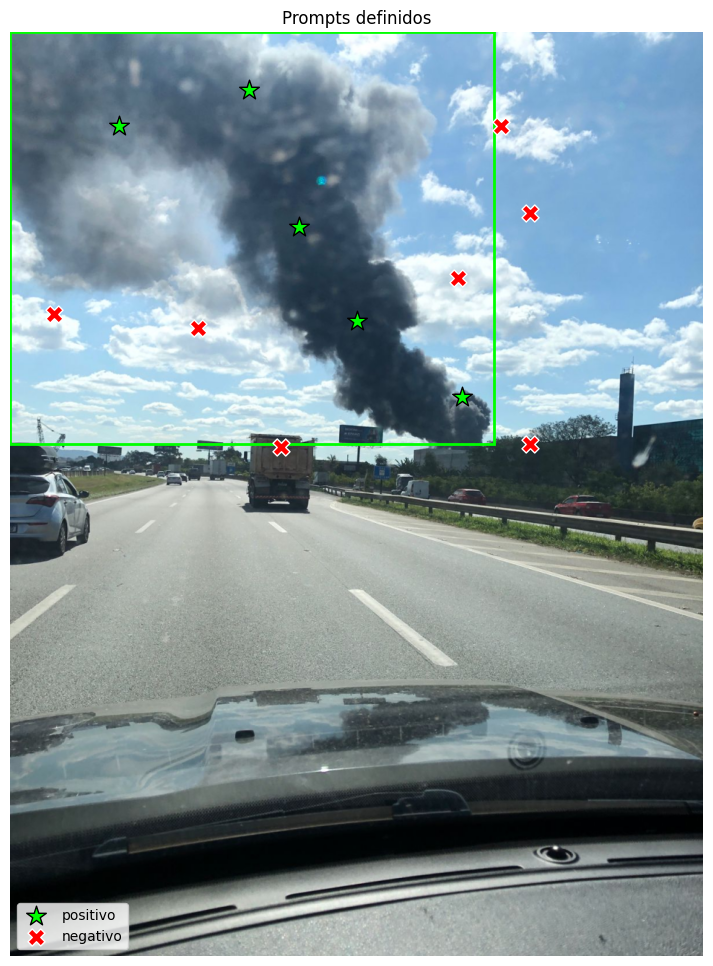

In [54]:
BOX = [0, 0, 670, 570]

POS = [[625, 505],   # base da pluma (fumaça mais densa e escura)
       [480, 400],   # meio da coluna
       [400, 270],   # parte alta da coluna
       [330,  80],   # topo, onde a pluma começa a se abrir
       [150, 130]]   # fumaça cinza espalhada para a esquerda

NEG = [[620, 340],   # nuvem branca à direita da coluna
       [720, 250],   # céu azul
       [680, 130],   # nuvem no alto à direita
       [ 60, 390],   # nuvem à esquerda
       [260, 410],   # nuvem abaixo da fumaça espalhada
       [375, 575],   # caminhão
       [720, 570]]   # árvores e prédio perto da base

fig, ax = plt.subplots(figsize=(9, 9 * H / W))
ax.imshow(img); desenhar_prompts(ax, BOX, POS + NEG, [1] * len(POS) + [0] * len(NEG))
ax.legend(loc="lower left"); ax.axis("off"); ax.set_title("Prompts definidos")
plt.show()

### 4.3 Prompt simples (um único ponto)

É o uso mais básico: um clique no meio da fumaça. Ele serve de referência para avaliar o que o SAM faz com pouca informação.

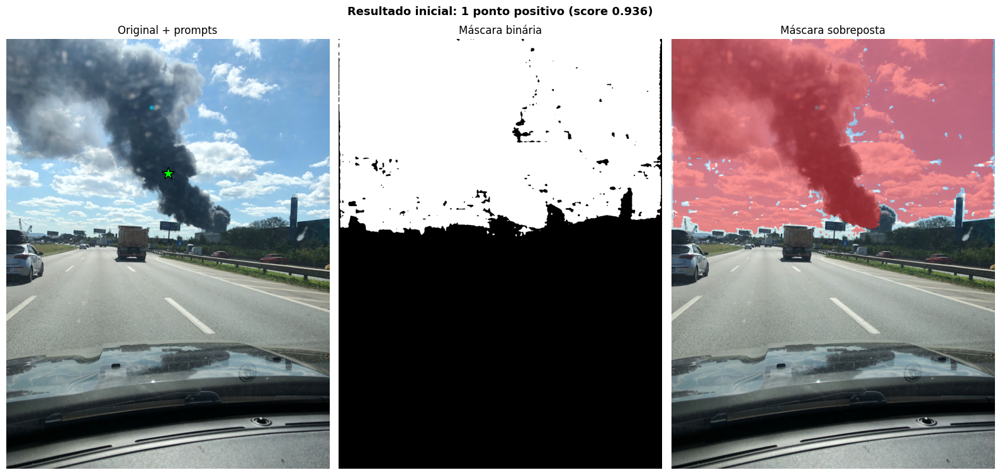

In [55]:
m0, s0, _ = segmentar(pts=POS[1:2], lbls=[1])
lado_a_lado(img, m0, f"Resultado inicial: 1 ponto positivo (score {s0:.3f})", pts=POS[1:2], lbls=[1])

**Avaliação do resultado inicial**

- **A máscara cobre a pluma?** Sim, mas por acidente. Com um único ponto no meio da coluna, o SAM devolveu uma máscara com **41,6 % da imagem**: a pluma, as nuvens e quase todo o céu azul, ou seja, tudo o que está acima do horizonte.
- **Inclui regiões que não pertencem a ela?** Muitas: céu e nuvens. O contraste local da máscara foi só 0,016, porque ela engoliu o próprio entorno da pluma.
- **Deixa partes da fumaça de fora?** Não, porque pegou demais.

Um ponto só é **ambíguo**: o SAM não sabe se queremos "a coluna escura", "a fumaça toda" ou "tudo acima do horizonte", e ficou com a maior região coerente. O score foi alto (**0,936**) mesmo com a máscara errada. O score mede a confiança do próprio modelo, não o acerto.

Na segmentação automática (4.1) aconteceu algo parecido: a fumaça cinza que se espalha para a esquerda foi agrupada **junto com o céu** numa região só, e a coluna escura nem recebeu uma máscara própria.

Numa primeira rodada, com os prompts em posições genéricas, um "ponto positivo" caiu no capô do carro, e o SAM segmentou o capô e o caminhão em vez da fumaça. **A posição dos prompts é decisiva.**

## 5. Comparação de configurações de prompt

Testamos quatro configurações, da mais simples para a mais completa. Para cada uma, aparece a imagem original com os prompts, a máscara binária e a máscara sobreposta.

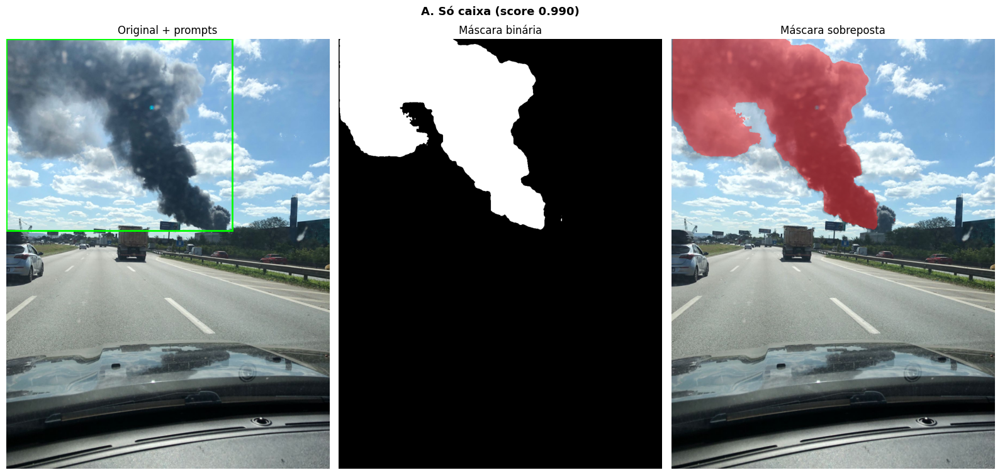

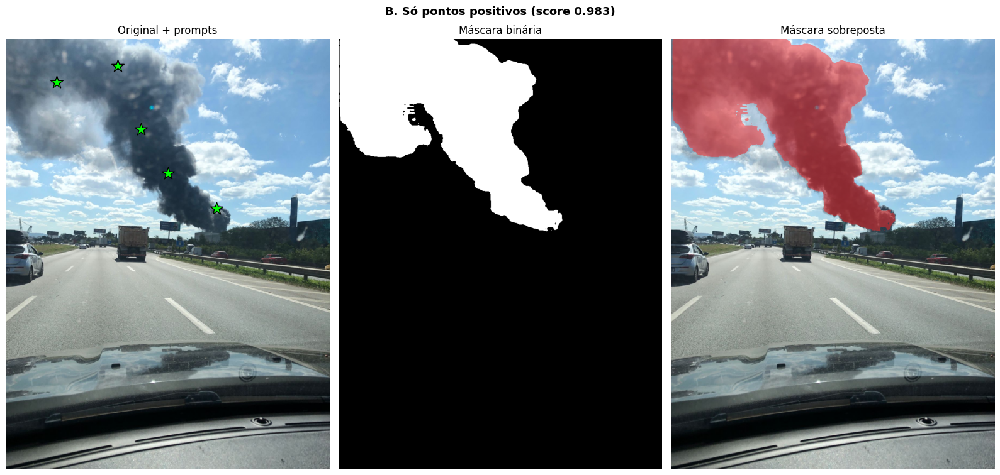

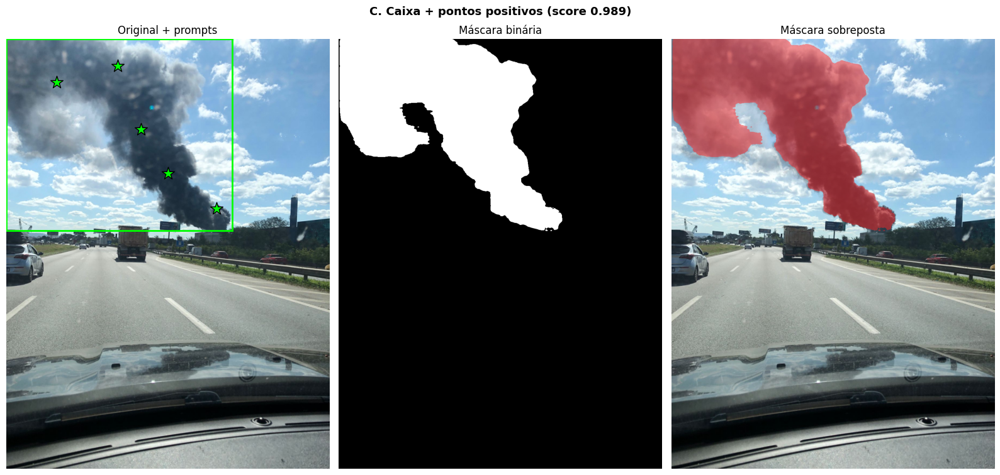

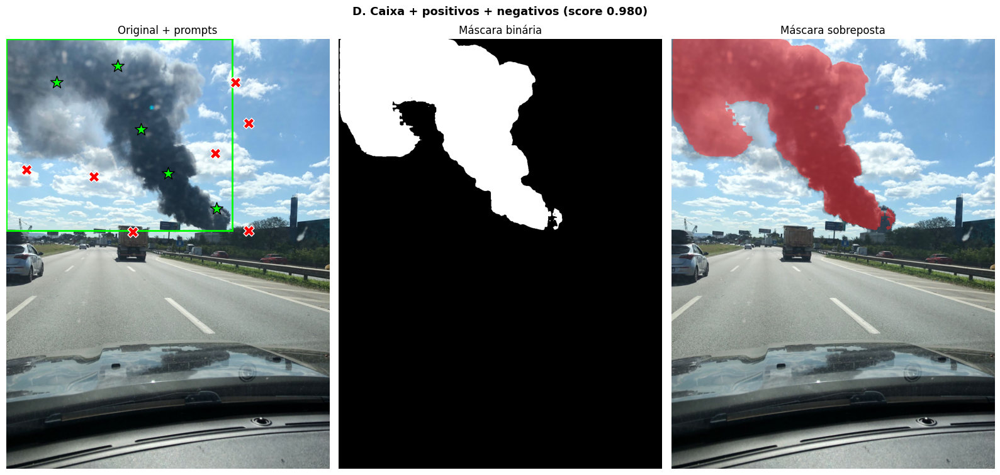

In [56]:
configs = {
    "A. Só caixa": dict(box=BOX),
    "B. Só pontos positivos": dict(pts=POS, lbls=[1] * len(POS)),
    "C. Caixa + pontos positivos": dict(box=BOX, pts=POS, lbls=[1] * len(POS)),
    "D. Caixa + positivos + negativos": dict(box=BOX, pts=POS + NEG,
                                             lbls=[1] * len(POS) + [0] * len(NEG)),
}

resultados, linhas = {}, [metricas("0. 1 ponto (inicial)", m0, s0)]
for nome, p in configs.items():
    m, s, lg = segmentar(**p)
    resultados[nome] = (m, s, lg)
    linhas.append(metricas(nome, m, s))
    lado_a_lado(img, m, f"{nome} (score {s:.3f})", **p)

### 5.1 Tabela comparativa

- **score SAM**: a confiança que o próprio modelo dá à máscara (0 a 1). É uma estimativa do modelo, não uma medida de acerto real.
- **componentes**: em quantos pedaços separados a máscara está. Uma pluma contínua deveria ser 1 ou poucos; muitos pedaços indicam ruído ou fragmentação.
- **IoU**: sobreposição entre duas máscaras (1 = iguais, 0 = nada em comum). Aqui comparamos cada uma com a configuração D.

In [57]:
ref = resultados["D. Caixa + positivos + negativos"][0]
tabela = pd.DataFrame(linhas)
tabela["IoU com D"] = [round(iou(m0, ref), 3)] + [round(iou(resultados[k][0], ref), 3) for k in configs]
tabela

,configuração,score SAM,área (% da imagem),componentes,lum. dentro,lum. anel,contraste local,IoU com D
0,0. 1 ponto (inicial),0.936,41.62,11,162.6,166.8,0.016,0.377
1,A. Só caixa,0.990,16.23,5,110.9,181.7,0.278,0.958
2,B. Só pontos positivos,0.983,16.72,4,111.6,183.4,0.282,0.947
3,C. Caixa + pontos positivos,0.989,16.52,5,110.4,184.2,0.290,0.960
4,D. Caixa + positivos + negativos,0.980,15.86,6,108.5,176.0,0.265,1.000


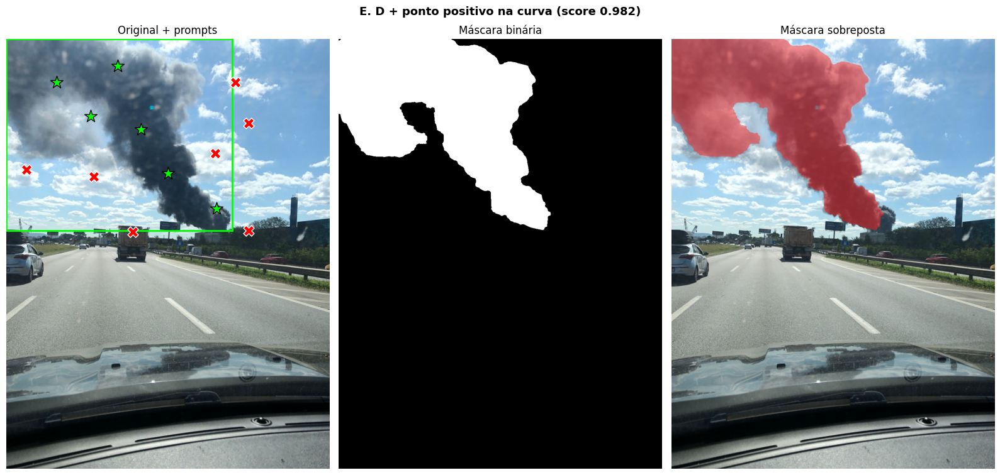

Área: D = 15.9 %  |  E = 16.1 %  |  IoU(D, E) = 0.974


In [58]:
# E: igual à D, mas com um ponto positivo extra na região clara entre a fumaça espalhada e a coluna
POS_E = POS + [[250, 230]]
pE = dict(box=BOX, pts=POS_E + NEG, lbls=[1] * len(POS_E) + [0] * len(NEG))
mE, sE, _ = segmentar(**pE)
mE = pos_processar(mE, POS_E)
lado_a_lado(img, mE, f"E. D + ponto positivo na curva (score {sE:.3f})", **pE)
print(f"Área: D = {100*ref.mean():.1f} %  |  E = {100*mE.mean():.1f} %  |  IoU(D, E) = {iou(ref, mE):.3f}")

## Teste E
Ponto positivo extra na região clara entre a fumaça espalhada e a coluna. Adicionamos um ponto positivo em (250, 230), numa região cinza-clara e semitransparente que ficou de fora da máscara D. Mesmo assim, o SAM manteve essa região fora. Ou seja, mesmo com a indicação explícita, o modelo trata essa parte como nuvem. Ali a fumaça é tão rala que fica com o mesmo brilho e a mesma cor das nuvens atrás dela, e não há como separar as duas só pela aparência. Como o ponto extra não mudou o resultado, mantivemos a configuração D com pós-processamento como máscara final.

## 6. Melhorias

### 6.1 Refinamento iterativo

O SAM devolve, além da máscara, uma versão em baixa resolução de "probabilidades" (*logits*). Se a passamos de volta como `mask_input`, junto com os mesmos prompts, o modelo corrige a própria máscara, normalmente reforçando bordas e preenchendo lacunas. É o procedimento sugerido no exemplo oficial do SAM.

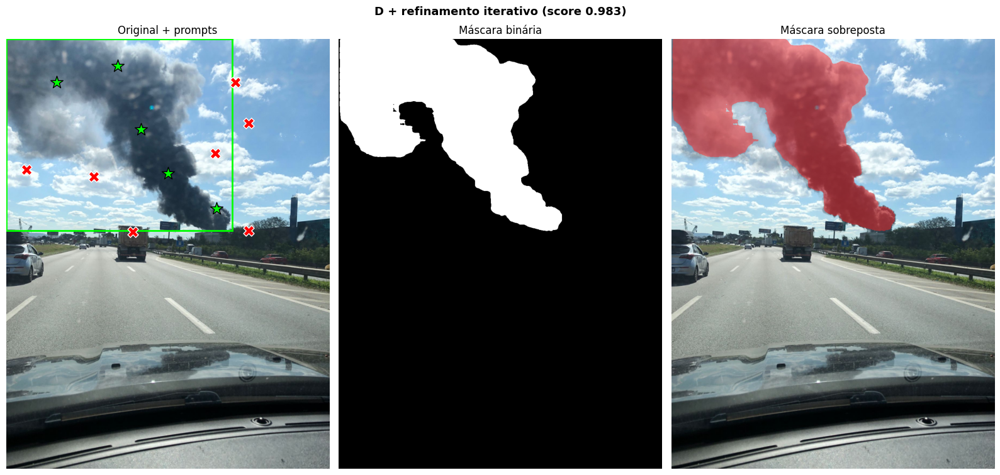

In [59]:
pD = configs["D. Caixa + positivos + negativos"]
_, _, logD = resultados["D. Caixa + positivos + negativos"]
m_ref, s_ref, _ = segmentar(**pD, mask_input=logD[None, :, :])
lado_a_lado(img, m_ref, f"D + refinamento iterativo (score {s_ref:.3f})", **pD)

### 6.2 Pós-processamento da máscara

Duas correções simples e justificáveis fisicamente:

1. **Remover pedaços isolados**: a pluma sai de uma fonte e é contínua, então manchas soltas longe dela costumam ser nuvem ou céu classificados por engano. Mantemos só os componentes que tocam um ponto positivo.
2. **Preencher buracos**: furos no meio da fumaça (partes mais claras ou mais escuras) não fazem sentido físico.

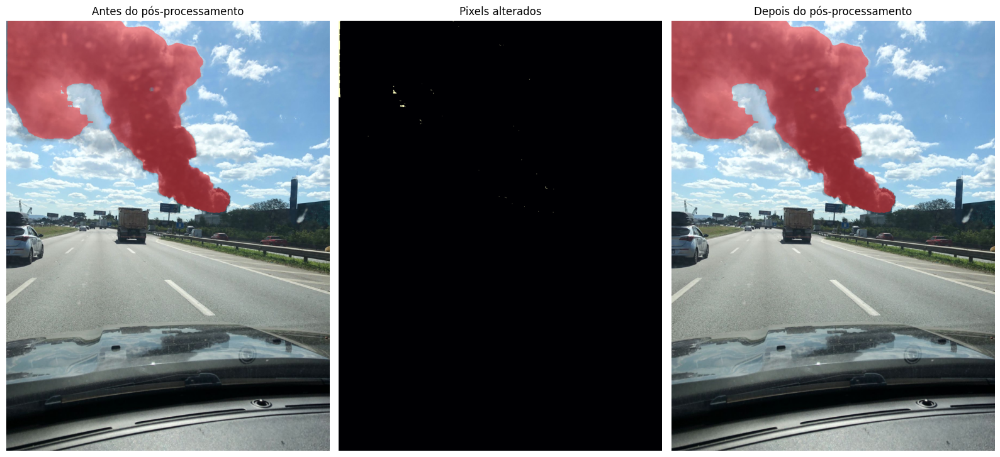

In [60]:
def pos_processar(mascara, pontos_positivos, raio_fechamento=5):
    rot, n = ndi.label(mascara)
    manter = {rot[y, x] for x, y in pontos_positivos if 0 <= y < H and 0 <= x < W and rot[y, x] > 0}
    if not manter:  # nenhum ponto caiu na máscara: fica o maior componente
        tamanhos = ndi.sum(mascara, rot, range(1, n + 1))
        manter = {int(np.argmax(tamanhos)) + 1}
    limpa = np.isin(rot, list(manter))
    elem = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * raio_fechamento + 1,) * 2)
    limpa = cv2.morphologyEx(limpa.astype(np.uint8), cv2.MORPH_CLOSE, elem).astype(bool)
    return ndi.binary_fill_holes(limpa)

m_pos = pos_processar(m_ref, POS)
fig, ax = plt.subplots(1, 3, figsize=(16, 5.3 * H / W + 0.8))
ax[0].imshow(sobrepor(img, m_ref)); ax[0].set_title("Antes do pós-processamento")
ax[1].imshow(m_ref ^ m_pos, cmap="magma"); ax[1].set_title("Pixels alterados")
ax[2].imshow(sobrepor(img, m_pos)); ax[2].set_title("Depois do pós-processamento")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 6.3 Realce de contraste (CLAHE) antes do SAM

Quando a fumaça tem brilho parecido com o céu ou com as nuvens, o modelo tem dificuldade em achar a borda. O **CLAHE** (equalização adaptativa de histograma) aumenta o contraste local sem estourar as áreas claras. Testamos a configuração D na imagem realçada para ver se o contraste é, de fato, parte do problema.

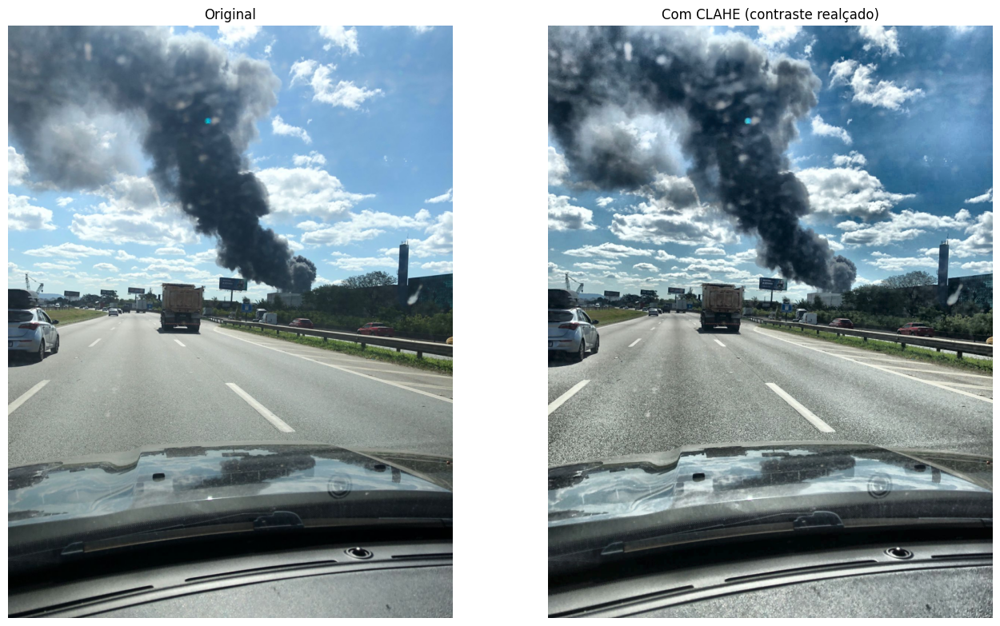

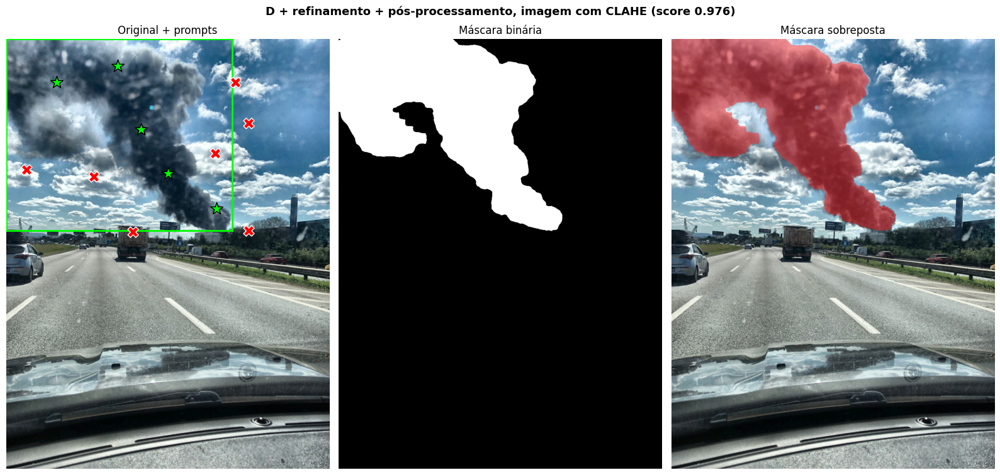

In [61]:
lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
l, a, b = cv2.split(lab)
clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
img_clahe = cv2.cvtColor(cv2.merge([clahe.apply(l), a, b]), cv2.COLOR_LAB2RGB)

predictor.set_image(img_clahe)
m_cl, s_cl, log_cl = segmentar(**pD)
m_cl, s_cl, _ = segmentar(**pD, mask_input=log_cl[None, :, :])
m_cl = pos_processar(m_cl, POS)
predictor.set_image(img)  # volta para a imagem original

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5 * H / W + 0.6))
ax[0].imshow(img); ax[0].set_title("Original")
ax[1].imshow(img_clahe); ax[1].set_title("Com CLAHE (contraste realçado)")
for a_ in ax: a_.axis("off")
plt.tight_layout(); plt.show()
lado_a_lado(img_clahe, m_cl, f"D + refinamento + pós-processamento, imagem com CLAHE (score {s_cl:.3f})", **pD)

### 6.4 Resumo das melhorias

In [62]:
m_pos_sem_ref = pos_processar(ref, POS)
finais = {"D (base)": (ref, resultados["D. Caixa + positivos + negativos"][1]),
          "D + pós-proc.": (m_pos_sem_ref, resultados["D. Caixa + positivos + negativos"][1]),
          "D + refinamento": (m_ref, s_ref),
          "D + refinamento + pós-proc.": (m_pos, s_ref),
          "D + CLAHE + refinamento + pós-proc.": (m_cl, s_cl)}
resumo = pd.DataFrame([metricas(k, m, s) for k, (m, s) in finais.items()])
resumo["IoU com D (base)"] = [round(iou(m, ref), 3) for m, _ in finais.values()]
resumo

,configuração,score SAM,área (% da imagem),componentes,lum. dentro,lum. anel,contraste local,IoU com D (base)
0,D (base),0.980,15.86,6,108.5,176.0,0.265,1.000
1,D + pós-proc.,0.980,15.89,1,108.8,179.9,0.279,0.988
2,D + refinamento,0.983,16.24,1,109.1,183.0,0.290,0.974
3,D + refinamento + pós-proc.,0.983,16.33,1,109.1,185.2,0.298,0.970
4,D + CLAHE + refinamento + pós-proc.,0.976,16.29,1,109.3,183.4,0.291,0.963


**Escolha da máscara final:** **D + pós-processamento.**

- A configuração D já acertava a pluma, mas em **6 pedaços**, com manchas soltas. O pós-processamento deixou **1 componente** quase sem mudar a área (15,9 %, IoU 0,988 com D).
- O **refinamento iterativo** mudou muito pouco nesta rodada (IoU 0,974). Na primeira rodada, com prompts ruins, ele chegou a **piorar** a máscara (score 0,94 → 0,72). Ou seja: ele só ajusta uma máscara que já está boa e não conserta uma ruim.
- O **CLAHE** (IoU 0,963) incluiu um pouco mais da fumaça escura à direita da base, que as outras versões deixavam de fora. Em compensação, ele realçou a sujeira e os reflexos do para-brisa. Como o ganho foi pequeno, ficamos com a versão mais simples.

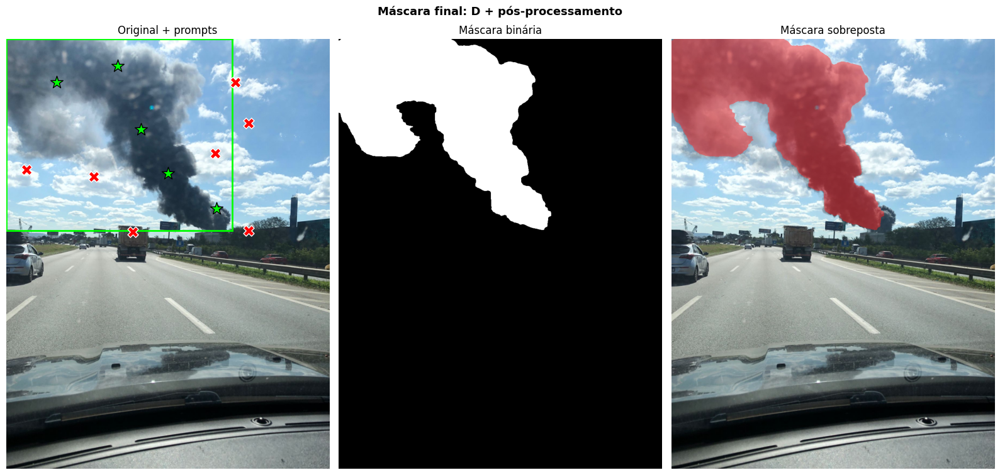

Salvos: mascara_pluma.png e mascara_pluma_sobreposta.png


In [63]:
# Opções: m_pos_sem_ref (D + pós-proc.), m_pos (D + refinamento + pós-proc.), m_cl (com CLAHE)
MASCARA_FINAL = m_pos_sem_ref
NOME_FINAL = "D + pós-processamento"

lado_a_lado(img, MASCARA_FINAL, f"Máscara final: {NOME_FINAL}", **pD)
Image.fromarray((MASCARA_FINAL * 255).astype(np.uint8)).save("mascara_pluma.png")
Image.fromarray(sobrepor(img, MASCARA_FINAL)).save("mascara_pluma_sobreposta.png")
print("Salvos: mascara_pluma.png e mascara_pluma_sobreposta.png")

## 7. Por que a segmentação é difícil? Iluminação, contraste e fumaça × nuvem

Fumaça e nuvem são ambas brancas ou cinzas, pouco saturadas (quase sem cor) e com bordas difusas. Para mostrar isso com números, comparamos três regiões em dois canais:

- **luminância** (brilho): quão clara é a região;
- **saturação** (canal S do HSV): quão "colorida" é a região.

As regiões são a **pluma** (máscara final), o **entorno imediato** (anel de 15 px em volta da máscara) e o **resto da imagem**. Se os histogramas da pluma e do entorno se sobrepõem muito, o modelo não tem como separar as duas coisas só pela aparência.

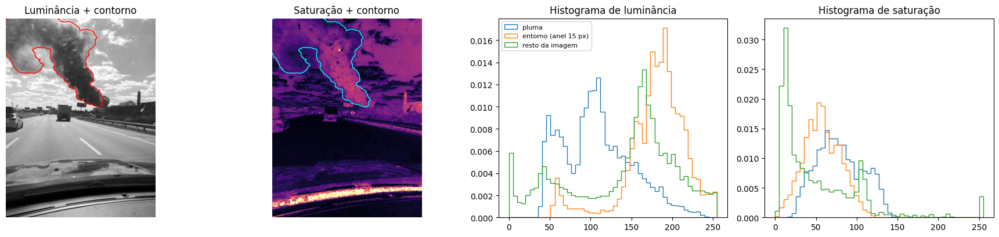

Sobreposição de histograma pluma × entorno: luminância = 0.31, saturação = 0.71  (0 = totalmente diferentes, 1 = idênticos)


,pluma,entorno (anel 15 px),resto da imagem
luminância média,108.8,179.9,141.0
luminância desvio,42.7,38.7,65.2
saturação média,79.0,57.8,50.7


In [64]:
SAT = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[..., 1].astype(float)
anel = ndi.binary_dilation(MASCARA_FINAL, iterations=15) & ~MASCARA_FINAL
fora = ~ndi.binary_dilation(MASCARA_FINAL, iterations=15)
regioes = {"pluma": MASCARA_FINAL, "entorno (anel 15 px)": anel, "resto da imagem": fora}

fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
ax[0].imshow(LUM, cmap="gray"); ax[0].contour(MASCARA_FINAL, colors="red", linewidths=1)
ax[0].set_title("Luminância + contorno"); ax[0].axis("off")
ax[1].imshow(SAT, cmap="magma"); ax[1].contour(MASCARA_FINAL, colors="cyan", linewidths=1)
ax[1].set_title("Saturação + contorno"); ax[1].axis("off")
for nome, r in regioes.items():
    ax[2].hist(LUM[r], bins=50, range=(0, 255), density=True, histtype="step", lw=2, label=nome)
    ax[3].hist(SAT[r], bins=50, range=(0, 255), density=True, histtype="step", lw=2, label=nome)
ax[2].set_title("Histograma de luminância"); ax[3].set_title("Histograma de saturação")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

def sobreposicao_hist(x, y, bins=50):
    hx, e = np.histogram(x, bins=bins, range=(0, 255)); hy, _ = np.histogram(y, bins=e)
    return np.minimum(hx / hx.sum(), hy / hy.sum()).sum()

print(f"Sobreposição de histograma pluma × entorno: luminância = {sobreposicao_hist(LUM[MASCARA_FINAL], LUM[anel]):.2f}, "
      f"saturação = {sobreposicao_hist(SAT[MASCARA_FINAL], SAT[anel]):.2f}  (0 = totalmente diferentes, 1 = idênticos)")
pd.DataFrame({n: {"luminância média": LUM[r].mean(), "luminância desvio": LUM[r].std(),
                  "saturação média": SAT[r].mean()} for n, r in regioes.items()}).round(1)

### 7.1 Discussão

**Qual configuração de prompt funcionou melhor e por quê?**
Com os prompts bem posicionados, as quatro configurações deram máscaras parecidas: IoU de 0,95 a 0,96 com a D, score entre 0,98 e 0,99, área entre 15,9 % e 16,7 %. O grande salto foi de **1 ponto (IoU 0,38) para qualquer uma delas**. Cada prompt ajudou de um jeito:
- a **caixa** limita a região e impede que o SAM pegue o céu inteiro;
- os **pontos positivos** espalhados da base ao topo garantem que a pluma entre inteira, inclusive a parte cinza à esquerda;
- os **pontos negativos** cortam pedaços de nuvem vizinha. A área caiu de 16,5 % (C) para 15,9 % (D).

Escolhemos a **D** por ser a mais controlada, já que dizemos explicitamente o que **não** é fumaça.

**Quais características da imagem dificultaram a segmentação?**
- **Bordas difusas:** a fumaça vai ficando rala até sumir. A parte cinza-clara embaixo da fumaça espalhada, à esquerda, se mistura com as nuvens e ficou de fora em todas as versões.
- **Pluma cortada:** o topo sai do quadro e a base fica escondida atrás das árvores e do prédio, então nenhuma máscara representa a pluma inteira.
- **Foto pelo para-brisa:** há reflexos, sujeira e um ponto de luz azulado bem no meio da coluna, que não são fumaça.
- **Céu cheio de nuvens** com formas parecidas com a da fumaça, inclusive coladas nela.

**Como a iluminação afetou?**
A mesma fumaça aparece com dois tons. O núcleo denso fica quase preto (luminância perto de 60) e a parte espalhada, mais fina e iluminada pelo sol, fica cinza (perto de 110). Por isso o histograma de luminância da pluma tem **dois picos**. A parte cinza fica parecida com a base sombreada das nuvens, e é ali que a máscara erra.

**Como o contraste afetou?**
No brilho, pluma e entorno são bem diferentes: a sobreposição dos histogramas de luminância é **0,31** (luminância média de 109 na pluma contra 180 no entorno). Por isso a coluna escura foi fácil de segmentar. O **CLAHE** quase não mudou o resultado (IoU 0,963), porque o problema não é falta de contraste geral. É a transição gradual na borda, onde não existe um limite nítido.

**Como a semelhança entre fumaça e nuvem afetou?**
Na cor, as duas são quase iguais: a sobreposição dos histogramas de saturação é **0,71**, porque fumaça e nuvem são acinzentadas e pouco coloridas. Onde a fumaça é rala e a nuvem tem sombra, nem brilho nem cor separam as duas, e sobram só a textura e a forma. É aí que os **pontos negativos** fazem diferença: eles dizem ao modelo qual daquelas massas cinzas não é a pluma. Isso também explica o resultado do modo automático, que juntou a fumaça espalhada com o céu.

## 8. Conclusões

- Sem prompts, ou com um ponto só, o SAM não sabe o que é "a pluma" e mistura fumaça, nuvem e céu. As tentativas automáticas da Parte B (YOLO e SAM 3 com texto) também falharam.
- Com **caixa + pontos positivos + pontos negativos** bem posicionados, a máscara cobre a coluna principal com cerca de 16 % da imagem, num único componente.
- O pós-processamento valeu a pena: tirou as manchas soltas sem alterar a pluma. O refinamento iterativo e o CLAHE quase não mudaram o resultado.
- **Limitações:** a máscara depende de onde os pontos são clicados; não temos uma máscara de referência desenhada à mão para medir o acerto real; a fumaça rala nas bordas continua de fora; a análise usa uma única foto.
